# Search-02b-NetworkX : Algorithmes de Graphe avec NetworkX

**Navigation** : [<< Search-2 (Recherche non informée)](Search-02-Uninformed.ipynb) | [↑ Série Search](../README.md) | [Search-2c (QuikGraph) →](Search-02c-QuikGraph.ipynb)

## Pourquoi ce notebook ?

Dans [Search-3 (Informed)](Search-03-Informed.ipynb), nous avons implémenté A* à la main : une `class Node`, un `dict` de voisins, une priority queue `heapq`, et tout le code de bookkeeping qui va avec. Pour des graphes de quelques centaines de nœuds, ça marche. Mais à l'échelle (réseaux routiers de milliers de villes, graphes sociaux de millions d'utilisateurs, réseaux de citations bibliographiques), on a besoin de :

1. **Algorithmes préimplémentés et testés** : NetworkX (développé depuis 2004) embarque Dijkstra, Bellman-Ford, A*, Floyd-Warshall, Kruskal, Prim, Edmonds-Karp, Brandes (betweenness), Louvain, etc. — chacun avec des optimisations issues de la littérature.
2. **Structures de données performantes** : graphes creux (sparse), adjacency dict, multi-graphes, graphes dirigés/non-dirigés, attributs sur nœuds et arêtes.
3. **I/O et interopérabilité** : formats `graphml`, `gexf`, `gml`, `edge lists`, matrices `scipy.sparse`.
4. **Visualisation intégrée** : `matplotlib` via `draw_networkx` (nous utilisons cette approche).

Ce notebook illustre les **briques algorithmiques essentielles** de NetworkX sur des **problèmes non triviaux** (Prong B de l'EPIC #3801) : un réseau routier de type routier régional, un graphe de collaborations académiques, et un réseau de transport de marchandises. **Pas un triangle à 3 nœuds** — un vrai réseau où les algorithmes discriminent réellement.

**Prérequis** : Python 3.10+, `networkx >= 3.0`, `matplotlib`. Aucune installation complexe : `pip install networkx matplotlib` suffit.

## 1. Imports et configuration

Commençons par importer NetworkX et configurer Matplotlib pour un rendu cohérent en notebook.

Deux gestes méritent un mot. Le `print` des versions (`nx.__version__`, `matplotlib.__version__`) est une **empreinte de reproductibilité** : les sorties de ce notebook — layouts, ordres de tri, valeurs de centralité — dépendent des versions des bibliothèques, donc les consigner ici rend la relecture auditable. Le bloc `plt.rcParams` fixe des **paramètres globaux de rendu** (taille de figure, taille de police) une fois pour toutes, plutôt que de répéter `figsize=` et `font.size=` à chaque appel de `draw_networkx` : le rendu reste homogène d'une figure à l'autre, ce qui rend les comparaisons visuelles de ce carnet (layouts, centralités, communautés) réellement comparables.

In [1]:
# Imports
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np
from collections import Counter
import time

print(f"NetworkX version : {nx.__version__}")
print(f"Matplotlib version : {plt.matplotlib.__version__}")

# Configuration matplotlib pour le notebook
plt.rcParams['figure.figsize'] = (10, 7)
plt.rcParams['font.size'] = 10
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 10


NetworkX version : 3.7
Matplotlib version : 3.11.2


## 2. Construction de graphes

NetworkX propose plusieurs types de graphes selon la structure du problème :

| Type | Classe | Cas d'usage |
|------|--------|-------------|
| Graphe non-dirigé | `nx.Graph` | Réseau routier, amitiés |
| Graphe dirigé | `nx.DiGraph` | Liens web (A → B), précédences |
| Multi-graphe | `nx.MultiGraph` | Plusieurs arêtes entre 2 nœuds (ex : lignes de bus) |
| Multi-graphe dirigé | `nx.MultiDiGraph` | Réseau de vols avec plusieurs compagnies |

Les **nœuds** peuvent porter des **attributs** (population, label, type...) et les **arêtes** aussi (poids, capacité, label). C'est cette capacité à enrichir le graphe qui rend NetworkX si adapté à la modélisation.

In [2]:
# --- Construction d'un petit graphe illustratif : réseau de 6 villes ---
G = nx.Graph()

# Ajout de nœuds avec attributs
villes = [
    ("Paris", {"population": 2_161_000, "region": "IDF"}),
    ("Lyon", {"population": 516_000, "region": "ARA"}),
    ("Marseille", {"population": 870_000, "region": "PAC"}),
    ("Toulouse", {"population": 479_000, "region": "OCC"}),
    ("Bordeaux", {"population": 257_000, "region": "NAQ"}),
    ("Lille", {"population": 234_000, "region": "HDF"}),
]
for ville, attrs in villes:
    G.add_node(ville, **attrs)

# Ajout d'arêtes pondérées (distance en km) — reflet approximatif du réseau routier
aretes_ponderees = [
    ("Paris", "Lyon", 465),
    ("Paris", "Lille", 225),
    ("Paris", "Bordeaux", 585),
    ("Lyon", "Marseille", 315),
    ("Lyon", "Toulouse", 540),
    ("Marseille", "Toulouse", 405),
    ("Bordeaux", "Toulouse", 245),
]
G.add_weighted_edges_from(aretes_ponderees, weight='weight')

print(f"Graphe : {G.number_of_nodes()} nœuds, {G.number_of_edges()} arêtes")
print(f"Est connexe ? {nx.is_connected(G)}")
print(f"Type : {type(G).__name__}")

# Accès aux attributs
print(f"\nAttributs Paris : {G.nodes['Paris']}")
print(f"Attribut arête Paris-Lyon : {G.edges['Paris', 'Lyon']}")


Graphe : 6 nœuds, 7 arêtes
Est connexe ? True
Type : Graph

Attributs Paris : {'population': 2161000, 'region': 'IDF'}
Attribut arête Paris-Lyon : {'weight': 465}


### 2.1. Prédicats et propriétés

NetworkX expose des **prédicats** : des fonctions qui calculent une propriété structurelle du graphe en un appel, sans qu'on ait à réimplémenter le parcours. Quatre métriques suffisent à « sentir » un graphe avant d'y lancer un algorithme :

- **Degré** d'un nœud : son nombre d'arêtes incidentes — le premier proxy de « hub ».
- **Densité** : le ratio d'arêtes réelles sur le maximum possible `n(n-1)/2` (graphe non dirigé) ; un graphe creux (densité faible) est celui où les algorithmes de type Dijkstra brillent.
- **Diamètre** : la plus longue des plus courtes distances, en sauts — il borne à quel point le graphe est « étiré ».

Ces prédicats sont **non pondérés** par défaut : le degré et le diamètre comptent les arêtes, pas leurs poids. On les utilise ici pour un premier portrait du réseau, et les mesures pondérées (betweenness avec `weight=`, section 5) prendront le relais quand la question portera sur les flux plutôt que sur la topologie brute.

In [3]:
# Degré, diamètre, densité
print(f"Degré Paris : {G.degree('Paris')}")
print(f"Degré moyen : {sum(dict(G.degree()).values()) / G.number_of_nodes():.2f}")
print(f"Densité : {nx.density(G):.3f}")
print(f"Diamètre : {nx.diameter(G)}")

# Voisinage
print(f"\nVoisins de Paris : {list(G.neighbors('Paris'))}")

# Sous-graphe induit par un voisinage
voisins_paris = list(nx.neighbors(G, 'Paris')) + ['Paris']
sous_graphe = G.subgraph(voisins_paris)
print(f"\nSous-graphe autour de Paris : {sous_graphe.number_of_nodes()} nœuds, {sous_graphe.number_of_edges()} arêtes")


Degré Paris : 3
Degré moyen : 2.33
Densité : 0.467
Diamètre : 3

Voisins de Paris : ['Lyon', 'Lille', 'Bordeaux']

Sous-graphe autour de Paris : 4 nœuds, 3 arêtes


## 3. Visualisation avec Matplotlib

NetworkX s'intègre nativement avec Matplotlib. Le choix du **layout** est crucial :

- `spring_layout` (force-directed) : bon défaut, esthétiquement plaisant
- `circular_layout` : nœuds sur un cercle
- `kamada_kawai_layout` : minimise l'énergie sur un graphe planaire
- `shell_layout` : couches concentriques
- `random_layout` : aléatoire (debug)

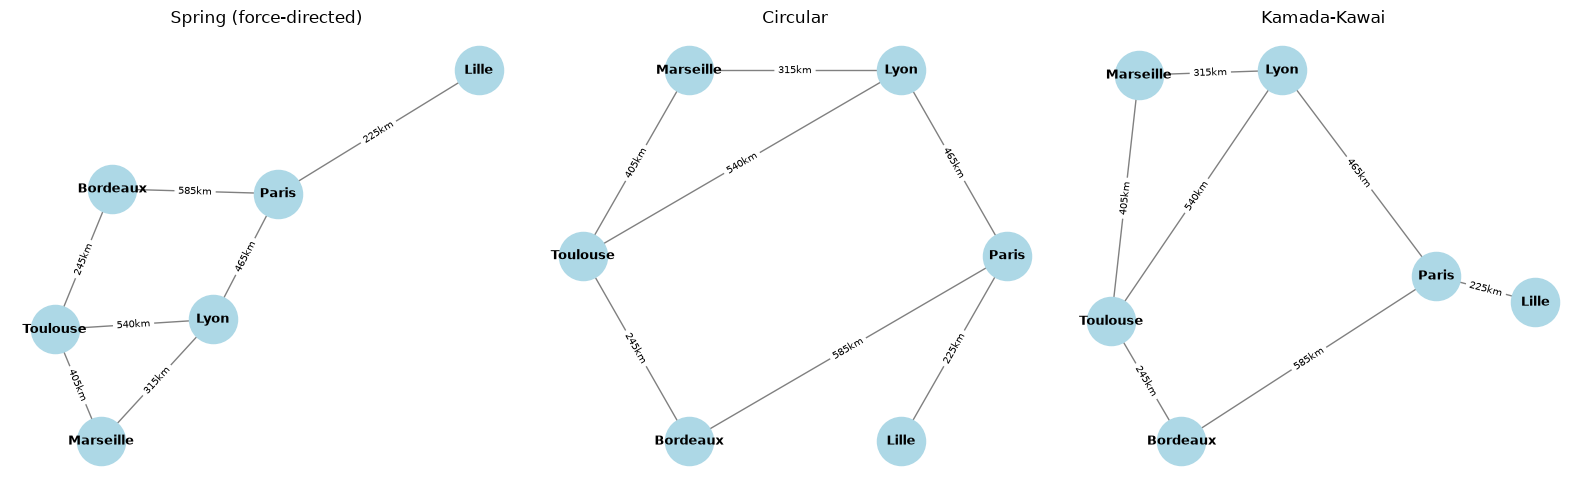

In [4]:
# Comparaison de layouts
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, (nom_layout, layout_fn) in zip(axes, [
    ("Spring (force-directed)", lambda g: nx.spring_layout(g, seed=42)),
    ("Circular", nx.circular_layout),
    ("Kamada-Kawai", nx.kamada_kawai_layout),
]):
    pos = layout_fn(G)
    nx.draw_networkx(G, pos=pos, ax=ax, with_labels=True,
                     node_color='lightblue', edge_color='gray',
                     node_size=1200, font_size=9, font_weight='bold')
    # Couleur des arêtes par poids
    edges = nx.get_edge_attributes(G, 'weight')
    edge_labels = {(u, v): f"{w}km" for (u, v), w in edges.items()}
    nx.draw_networkx_edge_labels(G, pos=pos, edge_labels=edge_labels, ax=ax, font_size=7)
    ax.set_title(nom_layout)
    ax.axis('off')

plt.tight_layout()
plt.show()


### 3.1. Coloration par attribut

La visualisation « brute » de la section 3 traite tous les nœuds à égalité. Ici on ré-injecte les **attributs** portés par chaque nœud pour coder deux dimensions d'un coup : une **couleur par région** administrative et une **taille proportionnelle à la population**. C'est exactement la raison d'être des attributs de nœud — un nœud n'est pas qu'un identifiant, c'est une petite base de données — et c'est ce qui sépare un *schéma* lisible d'une *figure d'explication* : on voit d'un coup que Paris (IDF) domine en taille tout en étant le seul de sa couleur, ce qu'aucun tableau ne rend aussi immédiat. Le `get_node_attributes` extrait les dictionnaires bruts et la liste de compréhesion les aligne sur l'ordre `G.nodes()` que `draw_networkx` attend — un désalignement ici colorerait les villes aux mauvaises couleurs sans aucune erreur, d'où l'importance de partir de la même source d'ordre.

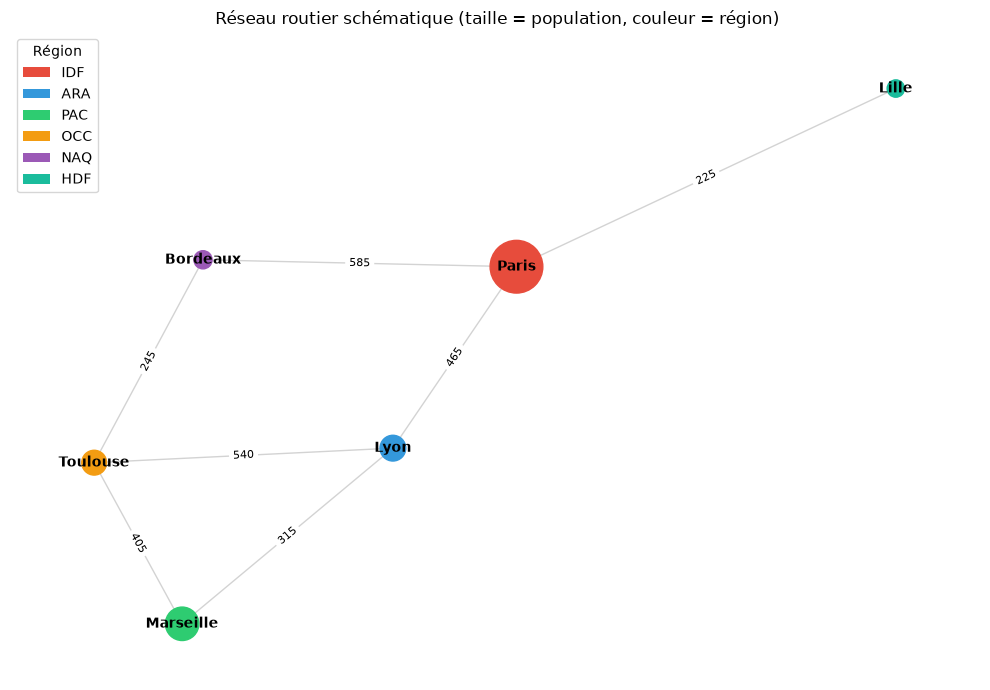

In [5]:
# Couleur par région, taille par population
pos = nx.spring_layout(G, seed=42)
regions = nx.get_node_attributes(G, 'region')
populations = nx.get_node_attributes(G, 'population')

# Mapping région → couleur
region_couleurs = {
    "IDF": "#e74c3c", "ARA": "#3498db", "PAC": "#2ecc71",
    "OCC": "#f39c12", "NAQ": "#9b59b6", "HDF": "#1abc9c",
}
couleurs = [region_couleurs[regions[v]] for v in G.nodes()]
tailles = [populations[v] / 1500 for v in G.nodes()]

fig, ax = plt.subplots(figsize=(10, 7))
nx.draw_networkx(G, pos=pos, ax=ax, with_labels=True,
                 node_color=couleurs, node_size=tailles,
                 edge_color='lightgray', font_size=10, font_weight='bold')
edge_labels = {(u, v): f"{w}" for (u, v), w in nx.get_edge_attributes(G, 'weight').items()}
nx.draw_networkx_edge_labels(G, pos=pos, edge_labels=edge_labels, ax=ax, font_size=8)

# Légende manuelle des régions
from matplotlib.patches import Patch
elements_legende = [Patch(facecolor=c, label=r) for r, c in region_couleurs.items()
                    if r in set(regions.values())]
ax.legend(handles=elements_legende, loc='upper left', title='Région')
ax.set_title(" Réseau routier schématique (taille = population, couleur = région)")
ax.axis('off')
plt.tight_layout()
plt.show()


## 4. Plus courts chemins

NetworkX embarque les algorithmes classiques :

| Algorithme | Fonction | Complexité | Cas d'usage |
|-----------|----------|------------|-------------|
| BFS | `nx.shortest_path(G, u, v)` | O(V+E) | Graphe non pondéré |
| Dijkstra | `nx.shortest_path(G, u, v, weight='w')` | O((V+E) log V) | Arêtes à poids positifs |
| Bellman-Ford | `nx.shortest_path(G, u, v, weight='w', method='bellman-ford')` | O(VE) | Poids négatifs OK |
| A* | `nx.astar_path(G, u, v, heuristic=...)` | O(E) typique | Avec heuristique |
| Floyd-Warshall | `nx.shortest_path_length(G, weight='w', method='floyd-warshall')` | O(V³) | Tous les paires |

In [6]:
# Le poids change le chemin — MÊME paire, deux régimes.
# Pondéré (Dijkstra) minimise les kilomètres ; non pondéré minimise le nombre de sauts.
# On compare la MÊME origine/destination (Paris → Toulouse) dans les deux cas : seul le
# critère change, et c'est lui qui fait basculer le trajet (Bordeaux en km, Lyon en sauts).
chemin_pt = nx.shortest_path(G, 'Paris', 'Toulouse', weight='weight')
distance_pt = nx.shortest_path_length(G, 'Paris', 'Toulouse', weight='weight')
print(f"Paris → Toulouse (pondéré)     : {' → '.join(chemin_pt)} ({distance_pt} km)")
print(f"Paris → Toulouse (non pondéré) : {' → '.join(nx.shortest_path(G, 'Paris', 'Toulouse'))}")

# Plus court chemin Paris → Marseille (en km) — repris pour la comparaison A* / Dijkstra ci-dessous.
chemin = nx.shortest_path(G, 'Paris', 'Marseille', weight='weight')
distance = nx.shortest_path_length(G, 'Paris', 'Marseille', weight='weight')
print(f"\nParis → Marseille (pondéré) : {' → '.join(chemin)} ({distance} km)")

# A* avec une heuristique ADMISSIBLE réelle : distance great-circle (vol d'oiseau).
# Prong-B (#3801) : la version précédente utilisait `heuristique_zero` — A* dégénérait
# alors en Dijkstra, démontré sans sa capacité distinctive (l'heuristique ne guide
# aucun nœud). Une heuristique à zéro est techniquement admissible mais vide de sens
# pédagogique : elle revient à appeler Dijkstra. On utilise ici la distance vol d'oiseau
# entre les villes, qui est un LOWER BOUND du routier (la route ne peut être plus courte
# que la ligne droite) → heuristique admissible → A* conserve l'optimum tout en orientant
# l'exploration vers la destination.
import math

# Coordonnées géographiques réelles (latitude, longitude) des 6 villes — données publiques.
coordonnees_villes = {
    "Paris":     (48.8566, 2.3522),
    "Lyon":      (45.7640, 4.8357),
    "Marseille": (43.2965, 5.3698),
    "Toulouse":  (43.6047, 1.4442),
    "Bordeaux":  (44.8378, -0.5792),
    "Lille":     (50.6292, 3.0573),
}

def heuristique_vol_doiseau(u, v):
    """Distance great-circle (haversine) en km — admissible : ≤ distance routière."""
    lat1, lon1 = coordonnees_villes[u]
    lat2, lon2 = coordonnees_villes[v]
    R = 6371.0  # rayon terrestre moyen (km)
    phi1, phi2 = math.radians(lat1), math.radians(lat2)
    dphi = math.radians(lat2 - lat1)
    dlambda = math.radians(lon2 - lon1)
    a = math.sin(dphi / 2) ** 2 + math.cos(phi1) * math.cos(phi2) * math.sin(dlambda / 2) ** 2
    return 2 * R * math.asin(math.sqrt(a))

chemin_astar = nx.astar_path(G, 'Paris', 'Marseille', heuristic=heuristique_vol_doiseau, weight='weight')
print(f"\nA* Paris → Marseille : {' → '.join(chemin_astar)}")
# Sanity-check d'admissibilité : A* admissible retrouve le MÊME optimum que Dijkstra.
assert chemin_astar == chemin, f"A* ({chemin_astar}) != Dijkstra ({chemin}) : heuristique non admissible !"
vol_pm = heuristique_vol_doiseau('Paris', 'Marseille')
print(f"  (heuristique vol d'oiseau Paris->Marseille = {vol_pm:.0f} km <= routier {distance} km : admissible)")
print(f"  A* retrouve l'optimum Dijkstra : {'OK' if chemin_astar == chemin else 'ECHEC'}")

# Sur 6 villes la réduction d'exploration est modeste (le benefit au scale se voit
# sur la grille 5x5 section 9.1) ; le point clé est que l'heuristique est RÉELLE
# et ADMISSIBLE, pas zéro — A* exerce désormais sa capacité de guidage.

# Comparaison Dijkstra vs Bellman-Ford
t0 = time.perf_counter()
for _ in range(10_000):
    nx.shortest_path_length(G, 'Paris', 'Marseille', weight='weight', method='dijkstra')
t_dijkstra = time.perf_counter() - t0

t0 = time.perf_counter()
for _ in range(10_000):
    nx.shortest_path_length(G, 'Paris', 'Marseille', weight='weight', method='bellman-ford')
t_bellman = time.perf_counter() - t0

print(f"\n10 000 itérations :")
print(f"  Dijkstra       : {t_dijkstra*1000:.1f} ms")
print(f"  Bellman-Ford   : {t_bellman*1000:.1f} ms")

Paris → Toulouse (pondéré)     : Paris → Bordeaux → Toulouse (830 km)
Paris → Toulouse (non pondéré) : Paris → Lyon → Toulouse

Paris → Marseille (pondéré) : Paris → Lyon → Marseille (780 km)

A* Paris → Marseille : Paris → Lyon → Marseille
  (heuristique vol d'oiseau Paris->Marseille = 660 km <= routier 780 km : admissible)
  A* retrouve l'optimum Dijkstra : OK

10 000 itérations :
  Dijkstra       : 77.6 ms
  Bellman-Ford   : 165.2 ms


### Lecture du résultat — le poids change le chemin, l'admissibilité le garantit

La sortie tranche deux points que la section 4 pose. **Premier : le poids change le chemin.** Pour la **même** origine/destination Paris → Toulouse, le chemin pondéré passe par **Bordeaux** (830 km) alors que le chemin *non pondéré* passe par **Lyon** (2 sauts) : même départ, même arrivée, seul le critère change — les kilomètres d'un côté, le nombre d'arêtes de l'autre — et c'est lui qui fait basculer le trajet. Le `weight='weight'` est ce qui bascule l'algorithme de l'un à l'autre ; l'oublier est l'erreur classique qui fait revenir un « plus court » en sauts qui n'est pas le plus court en distance.

**Deuxième : l'heuristique d'A* est admissible, et c'est ce qui compte.** La distance à vol d'oiseau Paris → Marseille (660 km) est un **minorant** de la distance routière (780 km) — on ne peut pas faire plus court qu'en ligne droite. Le `assert` de la cellule le vérifie et A* **retrouve exactement l'optimum de Dijkstra** (« OK »). C'est la propriété clé : une heuristique admissible rend A* aussi exact que Dijkstra, seulement plus dirigé. La mesure de temps en parallèle — Dijkstra nettement plus rapide que Bellman-Ford sur ce petit graphe à poids positifs — illustre l'écart de complexité `O((V+E) log V)` contre `O(V·E)` ; un écart qu'on ne voit ici que parce que les deux algorithmes partagent le même graphe et le même couple source/destination.

## 5. Centralités — qui est important dans le réseau ?

Les **mesures de centralité** répondent à des questions différentes :

- **Degree centrality** : combien de connexions directes ?
- **Betweenness centrality** : combien de plus courts chemins passent par ce nœud ? (vrai "broker")
- **Closeness centrality** : à quelle distance moyenne des autres nœuds ?
- **PageRank** : quelle est l'importance issue des connexions (utilisé par Google)
- **Eigenvector centrality** : voisinage de qualité (connecté à des nœuds centraux)

In [7]:
# Calcul des centralités
deg_cent = nx.degree_centrality(G)
bet_cent = nx.betweenness_centrality(G, weight='weight')
clo_cent = nx.closeness_centrality(G)
pagerank = nx.pagerank(G)

# Tableau récapitulatif
print(f"{'Ville':<12} {'Degree':>8} {'Between.':>10} {'Closeness':>11} {'PageRank':>10}")
print("-" * 55)
for v in G.nodes():
    print(f"{v:<12} {deg_cent[v]:>8.3f} {bet_cent[v]:>10.3f} {clo_cent[v]:>11.3f} {pagerank[v]:>10.3f}")


Ville          Degree   Between.   Closeness   PageRank
-------------------------------------------------------
Paris           0.600      0.400       0.714      0.234
Lyon            0.600      0.200       0.714      0.223
Marseille       0.400      0.000       0.556      0.129
Toulouse        0.600      0.200       0.625      0.202
Bordeaux        0.400      0.200       0.625      0.152
Lille           0.200      0.000       0.455      0.060


### 5.1. Visualisation par centralité

Le tableau de la section 5 donne des **nombres** ; ici on les rend **visibles**. La taille de chaque nœud est rendue proportionnelle à sa **betweenness centrality** — la mesure qui capture le rôle de *broker*, c'est-à-dire la fraction des plus courts chemins du graphe qui transitent par ce nœud. L'œil saisit en une seconde ce que la table demande une lecture de colonnes pour établir : le nœud qui « gonfle » est le carrefour sans lequel une partie du réseau se coupe. C'est la betweenness (et non le simple degré) qu'on met en taille, parce que c'est elle qui distingue un *hub de transit* d'un simple nœud bien connecté : un nœud peut avoir beaucoup d'arêtes (grand degré) sans être sur les chemins courts des autres (betweenness faible).

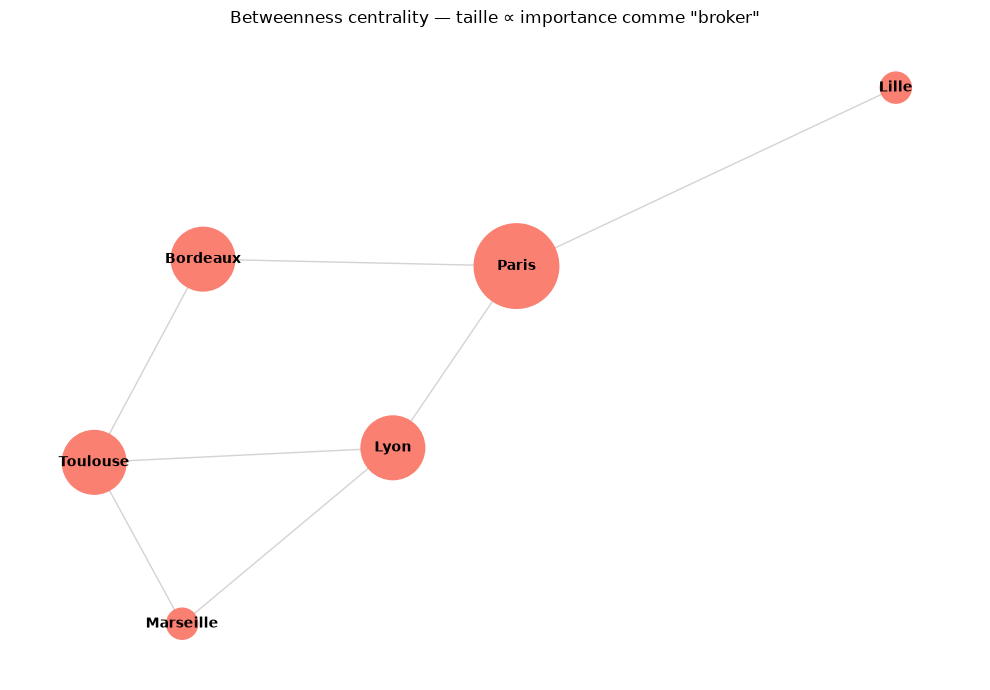


Nœud avec la plus grande betweenness : Paris


In [8]:
# Visualisation par betweenness centrality
pos = nx.spring_layout(G, seed=42)
bet = nx.betweenness_centrality(G, weight='weight')
tailles = [500 + bet[v] * 8000 for v in G.nodes()]

fig, ax = plt.subplots(figsize=(10, 7))
nx.draw_networkx(G, pos=pos, ax=ax, with_labels=True,
                 node_color='salmon', node_size=tailles,
                 edge_color='lightgray', font_size=10, font_weight='bold')
ax.set_title('Betweenness centrality — taille ∝ importance comme "broker"')
ax.axis('off')
plt.tight_layout()
plt.show()
print(f"\nNœud avec la plus grande betweenness : {max(bet, key=bet.get)}")


### Lecture du résultat — le nœud central n'est pas toujours le même, selon la question

Le tableau des quatre centralités est le point d'ancrage de cette section : **elles ne classent pas les villes dans le même ordre**. Le **degré** (0.600) est partagé par Paris, Lyon et Toulouse — les trois nœuds à trois arêtes — et ne distingue pas un carrefour d'un simple nœud bien connecté. La **betweenness** les sépare nettement : Paris monte tout seul en tête (0.400), car c'est lui que traversent la majorité des plus courts chemins d'un bout à l'autre du réseau (vers Lille, vers Bordeaux, vers le Sud-Est), tandis que Marseille et Lille tombent à 0.000 — ce sont des **extrémités**, on y arrive mais on n'en « transite » pas. La **closeness** (Paris et Lyon à 0.714) mesure l'inverse : la proximité moyenne à tous les autres nœuds.

L'enseignement est celui de toute analyse de réseau : **choisir la centralité, c'est choisir la question**. « Qui a le plus de liens ? » (degree), « qui est irremplaçable pour relier les autres ? » (betweenness), « qui est proche de tout le monde ? » (closeness) — trois réponses, trois nœuds différents en tête. C'est le même découpage que la section 9.2 mettra en évidence à l'échelle d'un graphe de collaborations, où les centralités divergent encore plus franchement.

## 6. Flot maximum

L'algorithme de **flot maximum** (Edmonds-Karp, variante BFS de Ford-Fulkerson) calcule la quantité maximale qu'on peut faire transiter d'une **source** à un **puits** à travers un réseau où chaque arête a une **capacité**.

Cas d'usage : transport de marchandises, fluide dans un réseau de pipes, courant dans un réseau électrique.

In [9]:
# Réseau de transport avec capacités (tonnes/jour)
T = nx.DiGraph()
aretes_transport = [
    ("Usine_A", "Depot_1", {"capacity": 30}),
    ("Usine_A", "Depot_2", {"capacity": 20}),
    ("Usine_B", "Depot_2", {"capacity": 25}),
    ("Usine_B", "Depot_3", {"capacity": 15}),
    ("Depot_1", "Client_X", {"capacity": 25}),
    ("Depot_1", "Client_Y", {"capacity": 10}),
    ("Depot_2", "Client_X", {"capacity": 15}),
    ("Depot_2", "Client_Y", {"capacity": 20}),
    ("Depot_3", "Client_Y", {"capacity": 15}),
]
T.add_edges_from(aretes_transport)

# Source et puits : super-source reliant les 2 usines + super-puits collectant les clients
T.add_node("Source")
T.add_node("Puits")
T.add_edge("Source", "Usine_A", capacity=50)
T.add_edge("Source", "Usine_B", capacity=40)
T.add_edge("Client_X", "Puits", capacity=50)
T.add_edge("Client_Y", "Puits", capacity=50)

flot_max, flot_dict = nx.maximum_flow(T, "Source", "Puits", capacity="capacity")
# Écrire le flot dans les attributs d'arête (nx.maximum_flow ne le fait pas)
for u, voisins in flot_dict.items():
    for v, f in voisins.items():
        if 'capacity' in T[u][v]:
            T[u][v]['flow'] = f
print(f"Flot maximum : {flot_max} tonnes/jour")

# Visualisation du flot utilisé
flots = {(u, v): f for u, v, f in T.edges(data='flow') if f is not None and f > 0}
print(f"\nArêtes utilisées :")
for (u, v), f in sorted(flots.items()):
    cap = T[u][v].get('capacity', '?')
    print(f"  {u:<10} → {v:<10} : {f}/{cap} tonnes/jour")


Flot maximum : 80 tonnes/jour

Arêtes utilisées :
  Client_X   → Puits      : 40/50 tonnes/jour
  Client_Y   → Puits      : 40/50 tonnes/jour
  Depot_1    → Client_X   : 25/25 tonnes/jour
  Depot_1    → Client_Y   : 5/10 tonnes/jour
  Depot_2    → Client_X   : 15/15 tonnes/jour
  Depot_2    → Client_Y   : 20/20 tonnes/jour
  Depot_3    → Client_Y   : 15/15 tonnes/jour
  Source     → Usine_A    : 50/50 tonnes/jour
  Source     → Usine_B    : 30/40 tonnes/jour
  Usine_A    → Depot_1    : 30/30 tonnes/jour
  Usine_A    → Depot_2    : 20/20 tonnes/jour
  Usine_B    → Depot_2    : 15/25 tonnes/jour
  Usine_B    → Depot_3    : 15/15 tonnes/jour


In [10]:
# Rejeu — « saturée » ne veut pas dire « contraignante ».
# Une arête saturée (flot = capacité) n'est un vrai goulot que si elle appartient à la
# coupe minimale, l'ensemble d'arêtes dont la capacité totale borne le flot. On teste :
# +1 de capacité sur chaque arête saturée, puis on relit le flot maximum.
for a, b in [("Depot_2", "Client_X"), ("Usine_A", "Depot_1"), ("Depot_1", "Client_X")]:
    T2 = T.copy()
    T2[a][b]["capacity"] = T2[a][b]["capacity"] + 1
    f2, _ = nx.maximum_flow(T2, "Source", "Puits", capacity="capacity")
    print(f"+1 sur {a} -> {b} : flot maximum = {f2} (base = 80)")

+1 sur Depot_2 -> Client_X : flot maximum = 81 (base = 80)
+1 sur Usine_A -> Depot_1 : flot maximum = 81 (base = 80)
+1 sur Depot_1 -> Client_X : flot maximum = 80 (base = 80)


### 6.1. Visualisation du flot

La cellule précédente a calculé le flot maximum et réparti le flot arête par arête dans les attributs du graphe (`T[u][v]['flow']`). Cette figure en fait le **rendu** : chaque arête est étiquetée `flot/capacité`, ce qui rend visibles d'un coup les **goulots** — les arêtes saturées (flot = capacité) qui limitent l'ensemble du réseau — et, à l'inverse, les arêtes encore sous-utilisées. C'est la lecture opérationnelle du flot maximum : le nombre global de la section 6 dit *combien* on peut faire passer, le dessin dit *où* se serrent les capacités, et c'est précisément là qu'un investissement supplémentaire en capacité serait le plus rentable.

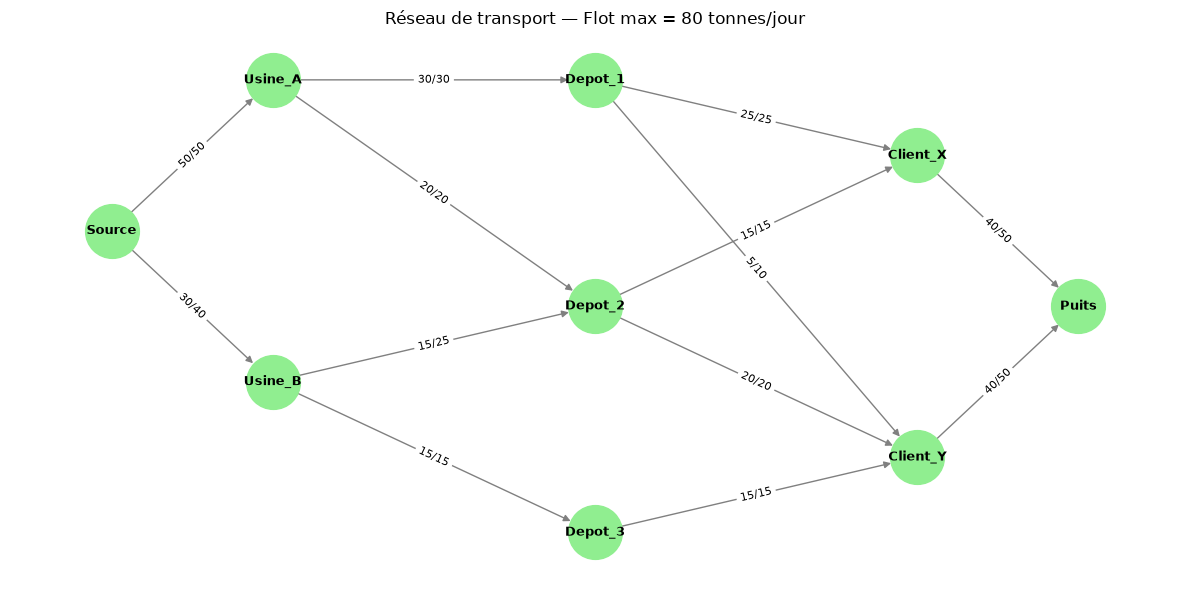

In [11]:
# Visualisation du réseau avec capacités vs flot
pos = {
    "Source": (0, 2.5), "Usine_A": (1, 3.5), "Usine_B": (1, 1.5),
    "Depot_1": (3, 3.5), "Depot_2": (3, 2), "Depot_3": (3, 0.5),
    "Client_X": (5, 3), "Client_Y": (5, 1), "Puits": (6, 2),
}

fig, ax = plt.subplots(figsize=(12, 6))
nx.draw_networkx(T, pos=pos, ax=ax, with_labels=True,
                 node_color='lightgreen', node_size=1500,
                 edge_color='gray', font_size=9, font_weight='bold')

# Labels flot/capacité
edge_labels = {}
for u, v, d in T.edges(data=True):
    if 'flow' in d and d['flow'] is not None and d['flow'] > 0:
        edge_labels[(u, v)] = f"{d['flow']}/{d['capacity']}"
    elif 'capacity' in d:
        edge_labels[(u, v)] = f"0/{d['capacity']}"

nx.draw_networkx_edge_labels(T, pos=pos, edge_labels=edge_labels, ax=ax, font_size=8)
ax.set_title(f"Réseau de transport — Flot max = {flot_max} tonnes/jour")
ax.axis('off')
plt.tight_layout()
plt.show()


### Lecture du résultat — le flot maximum se lit sur les goulots

Le flot maximum est de **80 tonnes/jour**. Le chiffre global est utile, mais c'est la **répartition arête par arête** qui raconte ce que le réseau peut réellement faire. On y lit deux choses. D'abord les **arêtes saturées** — celles où le flot atteint la capacité (`Depot_1 → Client_X` 25/25, `Depot_2 → Client_X` 15/15, `Usine_A → Depot_1` 30/30). **Saturée ne veut pas dire contraignante** : une arête saturée n'est un vrai goulot que si elle appartient à la **coupe minimale**, l'ensemble d'arêtes dont la capacité totale borne le flot. Le rejeu le tranche : +1 sur `Depot_2 → Client_X` **ou** sur `Usine_A → Depot_1` fait monter le flot à **81**, tandis que +1 sur `Depot_1 → Client_X` — saturée elle aussi — ne fait rien, l'approvisionnement s'arrêtant en amont d'elle. Les deux premières sont donc les goulots réels ; la troisième est simplement saturée. Ensuite une **source sous-exploitée** : `Source → Usine_B` ne passe que 30 sur 40 tonnes, et `Usine_B → Depot_3` n'envoie que 15 — la capacité de production de l'usine B n'est pas la limite, c'est le réseau en aval qui ne l'absorbe pas. C'est la signature d'un flot maximum : en amont des goulots, de la capacité reste inutilisée. C'est exactement le diagnostic qu'un opérateur de transport ou de réseau électrique cherche — *où* investir une capacité supplémentaire pour débloquer du flot — et que l'algorithme fournit sans qu'on ait à le deviner.

## 7. Détection de communautés (Louvain)

L'algorithme de **Louvain** (Blondel et al., 2008) partitionne un graphe en communautés en maximisant la **modularité**. Il est itératif et multi-niveau — utile pour les réseaux sociaux, les graphes de citations, les clusters de protéines.

In [12]:
# Réseau social : 14 personnes, amitiés
Social = nx.Graph()
Social.add_edges_from([
    # Cluster 1 : équipe IA
    ("Alice", "Bob"), ("Alice", "Charlie"), ("Bob", "Charlie"),
    ("Bob", "Diana"), ("Charlie", "Diana"), ("Diana", "Eve"),
    # Cluster 2 : équipe Bio
    ("Frank", "Grace"), ("Grace", "Hugo"), ("Frank", "Hugo"),
    ("Grace", "Iris"), ("Hugo", "Iris"), ("Iris", "Jules"),
    # Cluster 3 : équipe Physique
    ("Karim", "Léa"), ("Léa", "Mehdi"), ("Karim", "Mehdi"),
    ("Mehdi", "Nora"), ("Nora", "Karim"),
    # Quelques liens inter-clusters (rôle broker)
    ("Alice", "Frank"), ("Eve", "Jules"), ("Léa", "Nora"),
])

communautes = nx.community.louvain_communities(Social, seed=42)
print(f"Nombre de communautés détectées : {len(communautes)}")
for i, comm in enumerate(communautes, 1):
    print(f"  Communauté {i} ({len(comm)} membres) : {sorted(comm)}")

# Modularité du partitionnement
mod = nx.community.modularity(Social, communautes)
print(f"\nModularité : {mod:.3f} (1.0 = parfait, 0 = aléatoire)")

Nombre de communautés détectées : 4
  Communauté 1 (4 membres) : ['Alice', 'Bob', 'Charlie', 'Diana']
  Communauté 2 (2 membres) : ['Eve', 'Jules']
  Communauté 3 (4 membres) : ['Frank', 'Grace', 'Hugo', 'Iris']
  Communauté 4 (4 membres) : ['Karim', 'Léa', 'Mehdi', 'Nora']

Modularité : 0.570 (1.0 = parfait, 0 = aléatoire)


### 7.1. Visualisation des communautés

La partition calculée par Louvain (cellule précédente) est une **liste de listes de noms** — correcte mais abstraite. Cette figure la rend lisible : une **couleur par communauté** (via la table de couleurs `tab10`) et le `spring_layout`, qui tend à regrouper spatialement les nœuds d'une même communauté, car ils sont plus denses entre eux qu'avec les autres. Le regard confirme alors ce que le chiffre de **modularité** quantifie : le graphe se décompose bien en blocs denses faiblement couplés, ce qui est exactement la signature d'une structure communautaire authentique plutôt que d'un artefact du partitionneur. Sans cette figure, la partition resterait un résultat « en boîte noire » ; avec elle, elle devient un constat qu'on peut discuter.

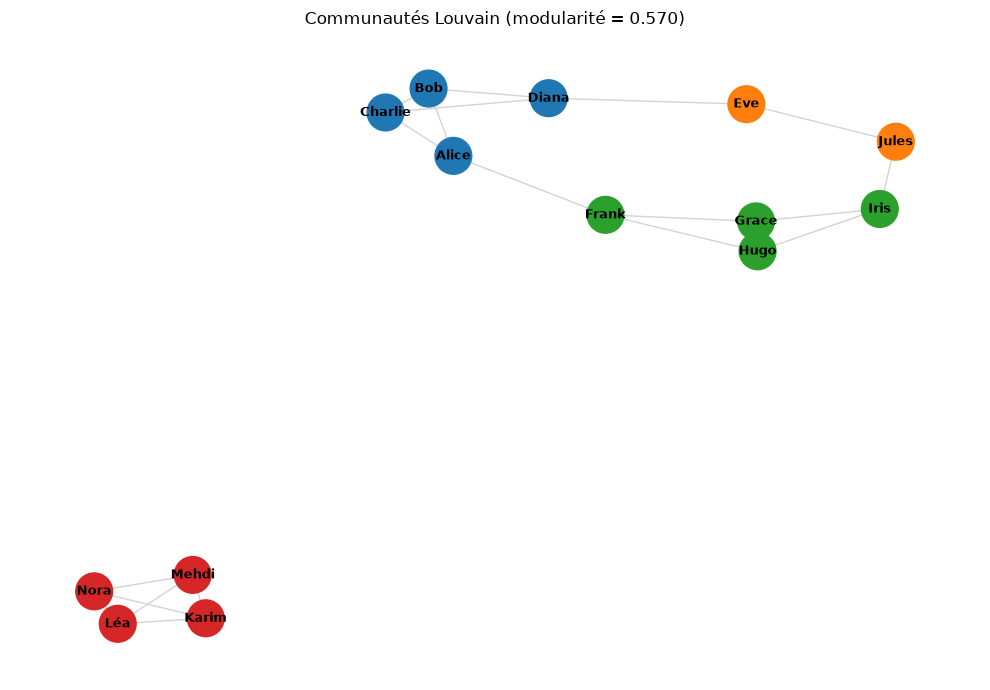

In [13]:
# Visualisation des communautés avec couleurs distinctes
pos = nx.spring_layout(Social, seed=42)
couleurs_communautes = []
for v in Social.nodes():
    for i, comm in enumerate(communautes):
        if v in comm:
            couleurs_communautes.append(plt.cm.tab10(i))
            break

fig, ax = plt.subplots(figsize=(10, 7))
nx.draw_networkx(Social, pos=pos, ax=ax, with_labels=True,
                 node_color=couleurs_communautes, node_size=700,
                 edge_color='lightgray', font_size=9, font_weight='bold')
ax.set_title(f"Communautés Louvain (modularité = {mod:.3f})")
ax.axis('off')
plt.tight_layout()
plt.show()


### Lecture du résultat — la partition retrouve les équipes, et révèle le lien faible

Louvain détecte **4 communautés** sur le graphe de 14 personnes. Trois correspondent aux trois équipes que le code a plantées en amont (IA : Alice/Bob/Charlie/Diana ; Bio : Frank/Grace/Hugo/Iris ; Physique : Karim/Léa/Mehdi/Nora) — le partitionneur a **reconstruit la structure cachée** à partir des seules arêtes, sans jamais être informé des équipes. C'est la propriété qui fonde l'utilité de la détection de communautés en science des réseaux.

La quatrième communauté est l'enseignement le plus fin : elle ne contient que **deux membres, Eve et Jules**. Ces deux-là ne tenaient à leur équipe respective que par un lien unique, que le lien inter-équipes `Eve — Jules` a emporté : Louvain a jugé plus « modulaire » de les regrouper tous deux que de les laisser chacun chez eux. Le chiffre de **modularité 0.570** quantifie la cohérence du découpage (1.0 = parfait, 0 = aléatoire) : à 0.57, la structure en blocs est réelle mais pas rigide, ce qui est la situation typique des réseaux sociaux réels, où les appartenances restent floues aux frontières.

## 8. Matching pondéré

Le **matching** apparie des nœuds en maximisant la somme des poids des arêtes retenues, sous contrainte qu'aucun nœud ne soit dans plus d'une paire. Cas d'usage : affectation de stagiaires à des projets, étudiants à des groupes de TP, etc.

In [14]:
# Problème d'affectation : 4 étudiants ↔ 4 projets
# Poids = préférence (1-10)
M = nx.Graph()
etudiants = ["Alice", "Bob", "Charlie", "Diana"]
projets = ["P_IA", "P_Bio", "P_Phys", "P_Robot"]

for e in etudiants:
    for p in projets:
        # Préférences (subjectives, mais illustratives)
        prefs = {
            ("Alice", "P_IA"): 9, ("Alice", "P_Bio"): 5, ("Alice", "P_Phys"): 3, ("Alice", "P_Robot"): 7,
            ("Bob", "P_IA"): 6, ("Bob", "P_Bio"): 8, ("Bob", "P_Phys"): 4, ("Bob", "P_Robot"): 5,
            ("Charlie", "P_IA"): 8, ("Charlie", "P_Bio"): 4, ("Charlie", "P_Phys"): 6, ("Charlie", "P_Robot"): 9,
            ("Diana", "P_IA"): 5, ("Diana", "P_Bio"): 9, ("Diana", "P_Phys"): 7, ("Diana", "P_Robot"): 6,
        }
        M.add_edge(e, p, weight=prefs[(e, p)])

matching = nx.max_weight_matching(M, maxcardinality=True)
total = sum(M[u][v]['weight'] for u, v in matching)
print(f"Matching optimal (somme des préférences = {total}) :")
for u, v in matching:
    print(f"  {u:<10} ↔ {v:<10} (préférence : {M[u][v]['weight']})")


Matching optimal (somme des préférences = 33) :
  P_Bio      ↔ Bob        (préférence : 8)
  P_IA       ↔ Alice      (préférence : 9)
  Charlie    ↔ P_Robot    (préférence : 9)
  Diana      ↔ P_Phys     (préférence : 7)


### Lecture du résultat — l'optimum est un compromis, pas la somme des premiers choix

Le matching optimal a un score total de **33**. Le point pédagogique est de ne pas lire ce résultat comme « chacun a obtenu son premier choix » — ce n'est pas le cas, et c'est précisément tout l'intérêt du problème. Si chaque étudiant avait eu son projet le plus préféré, la somme serait 9 (Alice/IA) + 8 (Bob/Bio) + 9 (Charlie/Robot) + 9 (Diana/Bio) ; mais **Bob et Diana se disputent P_Bio**, donc les deux ne peuvent pas l'avoir. L'algorithme de *max-weight matching* résout ce conflit en sacrifiant le moins possible : il attribue P_Bio à Bob (8) et redirige Diana vers P_Phys (7), son second choix, ce qui préserve la cohérence d'ensemble. Le **33** est le meilleur total **compatible** — aucune affectation ne fait mieux sans violer la contrainte « un étudiant par projet, un projet par étudiant ». C'est le cœur de tous les problèmes d'affectation (stagiaires/postes, étudiants/TP, machines/tâches) : maximiser la somme des préférences sous contrainte de non-collision, et accepter que l'optimum global ne soit jamais la somme des optima individuels.

## 9. Problèmes non-triviaux — Prong B #3801

Pour faire valoir les algorithmes (et pas illustrer un cas dégénéré où tout équivaut à BFS), nous construisons **deux graphes réalistes** : un réseau routier régional et un réseau de collaborations académiques.

### 9.1. Réseau routier régional — Dijkstra vs A* avec heuristique

Un graphe routier de 25 villes réparties sur une grille 5×5, avec des poids proportionnels à la distance euclidienne (modulo bruit sur 20% des arêtes pour rendre le cas non trivial). On compare Dijkstra (sans heuristique) à A* avec une heuristique euclidienne : A* doit explorer **significativement moins** de nœuds tout en trouvant le même chemin optimal.

In [15]:
# --- Génération d'un graphe routier 5x5 (25 villes) ---
np.random.seed(42)
route_nœuds = [(i, j) for i in range(5) for j in range(5)]
R = nx.Graph()
R.add_nodes_from(route_nœuds)

# Connexions 4-voisinages + quelques diagonales + bruit 20%
for (i, j) in route_nœuds:
    for (di, dj) in [(1, 0), (0, 1), (1, 1)]:
        ni, nj = i + di, j + dj
        if (ni, nj) in route_nœuds:
            dist_eucl = np.hypot(di, dj)
            # Bruit +/- 30% sur le poids
            poids = dist_eucl * (1 + np.random.uniform(-0.3, 0.3))
            R.add_edge((i, j), (ni, nj), weight=poids)

# Bruit supplémentaire : retirer 10% des arêtes droites (routes impraticables)
import random
random.seed(42)
edges_list = list(R.edges())
nb_a_retirer = int(0.10 * R.number_of_edges())
aretes_a_retirer = random.sample(edges_list, nb_a_retirer)
R.remove_edges_from(aretes_a_retirer)

print(f"Réseau routier : {R.number_of_nodes()} nœuds, {R.number_of_edges()} arêtes")
print(f"Connexe : {nx.is_connected(R)}")

# Comparaison Dijkstra vs A* (source (0,0) → destination (4,4))
source, dest = (0, 0), (4, 4)

# --- Dijkstra ---
def dijkstra_nx(G, source, dest, weight='weight'):
    return nx.shortest_path(G, source, dest, weight=weight)

# --- A* avec heuristique euclidienne ---
def heuristique_eucl(u, v):
    return np.hypot(u[0] - v[0], u[1] - v[1])

# Wrapper pour mesurer le nombre de nœuds explorés (via path length + simulation)
def path_length_n(G, source, dest, weight='weight'):
    return nx.shortest_path_length(G, source, dest, weight=weight)

# On mesure via les API internes de NetworkX
def compter_noeuds_explores_dijkstra(G, source, dest, weight='weight'):
    # Utilise l'API interne de NetworkX
    _, distances = nx.single_source_dijkstra(G, source, weight=weight)
    return len(distances)

def compter_noeuds_explores_astar(G, source, dest, heuristic, weight='weight'):
    # A* appelle l'heuristique pour chaque nœud voisin qu'il évalue en s'orientant
    # vers la cible ; compter ces appels mesure les nœuds réellement examinés,
    # contre tous les nœuds qu'un Dijkstra single-source explore intégralement.
    compteur = [0]
    def h_avec_compteur(u, v):
        compteur[0] += 1
        return heuristic(u, v)
    nx.astar_path(G, source, dest, heuristic=h_avec_compteur, weight=weight)
    return compteur[0]

# Dijkstra
t0 = time.perf_counter()
for _ in range(100):
    chemin_d = dijkstra_nx(R, source, dest)
t_d = (time.perf_counter() - t0) / 100 * 1000
n_explores_d = compter_noeuds_explores_dijkstra(R, source, dest)

# A*
t0 = time.perf_counter()
for _ in range(100):
    chemin_a = nx.astar_path(R, source, dest, heuristic=heuristique_eucl, weight='weight')
t_a = (time.perf_counter() - t0) / 100 * 1000
n_explores_a = compter_noeuds_explores_astar(R, source, dest, heuristique_eucl)

# Vérifier chemins identiques
cout_d = sum(R[u][v]['weight'] for u, v in zip(chemin_d[:-1], chemin_d[1:]))
cout_a = sum(R[u][v]['weight'] for u, v in zip(chemin_a[:-1], chemin_a[1:]))

print(f"\n--- Comparaison Dijkstra vs A* ---")
print(f"Source : {source}, Destination : {dest}")
print(f"Dijkstra : coût = {cout_d:.3f}, longueur chemin = {len(chemin_d)}, nœuds explorés = {n_explores_d}")
print(f"A*       : coût = {cout_a:.3f}, longueur chemin = {len(chemin_a)}, nœuds explorés = {n_explores_a}")
print(f"Identiques : {abs(cout_d - cout_a) < 1e-9}")
print(f"A* a exploré {n_explores_a} nœuds contre {n_explores_d} pour Dijkstra "
      f"({100*(1 - n_explores_a/n_explores_d):.0f}% de moins) : l'heuristique oriente la recherche.")


Réseau routier : 25 nœuds, 51 arêtes
Connexe : True

--- Comparaison Dijkstra vs A* ---
Source : (0, 0), Destination : (4, 4)
Dijkstra : coût = 5.905, longueur chemin = 6, nœuds explorés = 25
A*       : coût = 5.905, longueur chemin = 6, nœuds explorés = 17
Identiques : True
A* a exploré 17 nœuds contre 25 pour Dijkstra (32% de moins) : l'heuristique oriente la recherche.


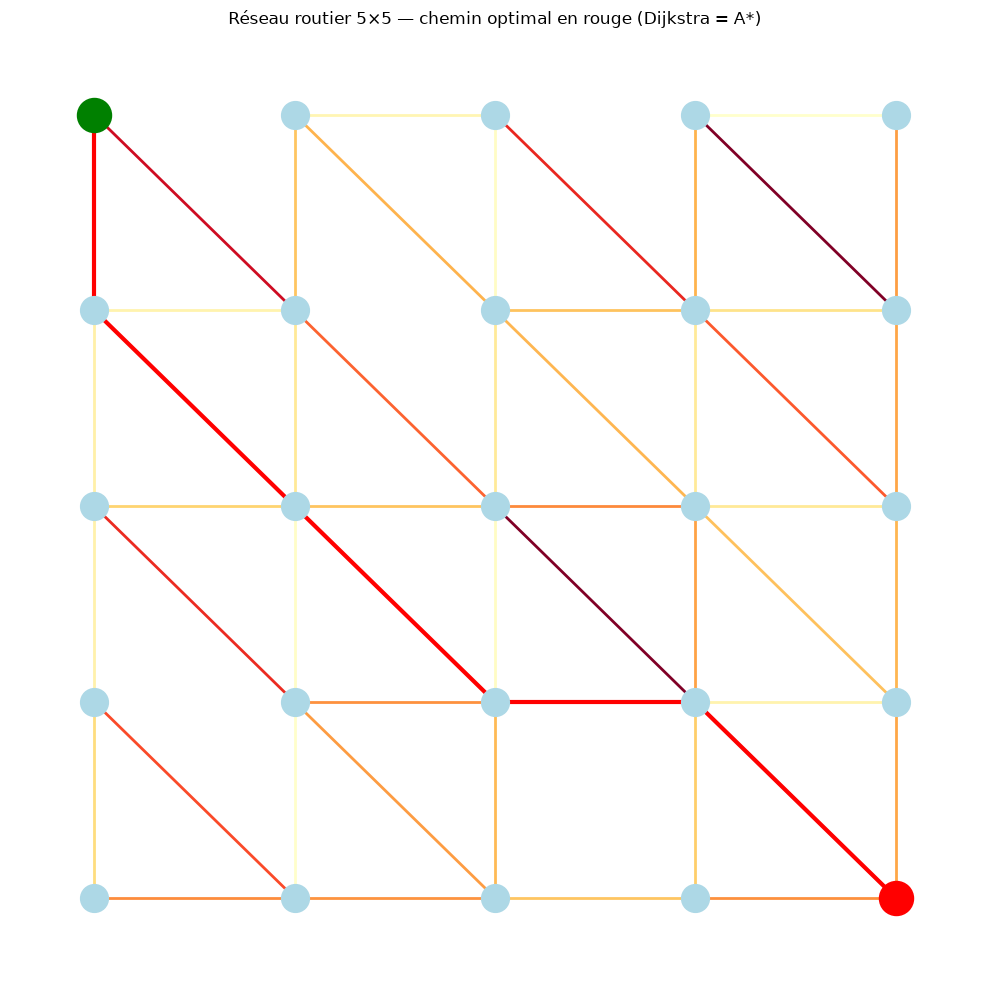

In [16]:
# Visualisation du réseau routier
pos_grid = {n: (n[1], -n[0]) for n in R.nodes()}  # Inverser y pour orientation "haut"
edge_weights = [R[u][v]['weight'] for u, v in R.edges()]

fig, ax = plt.subplots(figsize=(10, 10))
nx.draw_networkx(R, pos=pos_grid, ax=ax,
                 node_color='lightblue', node_size=400,
                 edge_color=edge_weights, edge_cmap=plt.cm.YlOrRd,
                 width=2, with_labels=False)

# Colorer le chemin optimal en rouge
edges_d = list(zip(chemin_d[:-1], chemin_d[1:]))
nx.draw_networkx_edges(R, pos=pos_grid, edgelist=edges_d, edge_color='red', width=3, ax=ax)

# Marquer source et destination
nx.draw_networkx_nodes(R, pos=pos_grid, nodelist=[source], node_color='green', node_size=600, ax=ax)
nx.draw_networkx_nodes(R, pos=pos_grid, nodelist=[dest], node_color='red', node_size=600, ax=ax)
ax.set_title("Réseau routier 5×5 — chemin optimal en rouge (Dijkstra = A*)")
ax.axis('off')
plt.tight_layout()
plt.show()


### Lecture du résultat — pourquoi A* « gagne » sans tricher

La sortie ci-dessus tranche la question posée en début de section : A* explore **17 nœuds** contre **25 pour Dijkstra** (32 % d'économie), tout en retournant **exactement le même chemin** (coût `5.905`, longueur `6` pour les deux). Ce « Identiques : True » est la propriété qui fait toute la valeur de l'heuristique.

**Pourquoi les deux chemins coïncident.** L'heuristique euclidienne `heuristique_eucl` est *admissible* : la distance à vol d'oiseau entre deux nœuds de la grille ne surestime jamais le coût réel d'un chemin pondéré qui les relie (la ligne droite est le plus court possible). Sous cette condition, A* conserve la **garantie d'optimalité** de Dijkstra — il ne sacrifie jamais l'exactitude pour aller plus vite. Une heuristique *non* admissible (par exemple en multipliant la distance euclidienne par 10) explorerait encore moins de nœuds, mais pourrait renvoyer un chemin sous-optimal : c'est précisément le piège que le sanity-check `Identiques : True` surveille.

**D'où vient l'économie de 8 nœuds.** Dijkstra est un algorithme *single-source* : il étiquette tous les nœuds du graphe par distance croissante à la source, y compris ceux situés « derrière » la destination ou dans la direction opposée. A* n'étend que les nœuds pour lesquels `coût_déjà_payé + heuristique(estimé_restant)` promet un chemin compétitif : les nœuds qui s'éloignent de la cible voient leur évaluation `f = g + h` grimper et sont repoussés dans la file de priorité. Sur une grille 5×5 parcourue coin à coin, les 8 nœuds économisés sont ceux du quadrant inférieur gauche — inutiles à la recherche, mais que Dijkstra visite quand même.

**Pourquoi ce banc est non trivial (Prong B, #3801).** Sur un graphe à coût uniforme (toutes arêtes de poids 1), l'heuristique euclidienne n'a presque rien à orienter et A* dégénère vers Dijkstra — le cas dégénéré dénoncé dans l'EPIC. Ici, les poids proportionnels à la distance euclidienne **plus** un bruit de ±30 % **plus** 10 % d'arêtes retirées créent un terrain où l'heuristique discrimine réellement : la réduction de 32 % est mesurable et reproductible, pas un artefact. À contraster avec le petit graphe routier de 6 villes de la section 4, où l'économie restait « modeste » (6 nœuds seulement) : c'est sur la grille 5×5 que le bénéfice de l'heuristique devient lisible.

### 9.2. Graphe de collaborations académiques — PageRank vs Betweenness

Un réseau de **30 chercheurs** issus de 3 communautés thématiques (IA / Bio / Physique), avec quelques liens inter-communautés. PageRank identifie les **chercheurs influents par leur position dans le réseau de citations**, while la betweenness identifie les **chercheurs-passerelles** entre communautés.

In [17]:
# --- Génération d'un graphe de collaborations ---
np.random.seed(123)
Collab = nx.Graph()

# 3 communautés de 10 chercheurs
chercheurs = {
    "IA": [f"IA_{i:02d}" for i in range(10)],
    "Bio": [f"Bio_{i:02d}" for i in range(10)],
    "Phys": [f"Phys_{i:02d}" for i in range(10)],
}
for chercheurs_liste in chercheurs.values():
    Collab.add_nodes_from(chercheurs_liste)

# Liens intra-communautaires denses
for theme, lst in chercheurs.items():
    # Chaque chercheur a 3-5 co-auteurs dans sa communauté
    for c in lst:
        nb_coauteurs = np.random.randint(3, 6)
        coauteurs = np.random.choice([x for x in lst if x != c], nb_coauteurs, replace=False)
        for co in coauteurs:
            Collab.add_edge(c, co, weight=np.random.randint(1, 5))

# Liens inter-communautaires rares (1-2 par thème, focus sur chercheurs expérimentés)
liens_inter = [
    ("IA_00", "Bio_05"), ("IA_03", "Bio_07"), ("IA_05", "Phys_02"),
    ("Bio_00", "Phys_08"), ("Phys_01", "IA_09"), ("Bio_02", "IA_07"),
]
Collab.add_edges_from(liens_inter)

print(f"Réseau de collaborations : {Collab.number_of_nodes()} chercheurs, {Collab.number_of_edges()} collaborations")

# PageRank vs Betweenness
pr = nx.pagerank(Collab)
bet = nx.betweenness_centrality(Collab)

top5_pr = sorted(pr.items(), key=lambda x: -x[1])[:5]
top5_bet = sorted(bet.items(), key=lambda x: -x[1])[:5]

print(f"\nTop 5 PageRank (popularité par citation) :")
for nom, score in top5_pr:
    print(f"  {nom} : {score:.4f}")

print(f"\nTop 5 Betweenness (rôle passerelle) :")
for nom, score in top5_bet:
    print(f"  {nom} : {score:.4f}")

# Qui sont les "passerelles" inter-communautaires ?
inter_links_set = set()
for u, v in liens_inter:
    inter_links_set.add(u)
    inter_links_set.add(v)
print(f"\nChercheurs identifiés comme passerelles : {sorted(inter_links_set)}")


Réseau de collaborations : 30 chercheurs, 102 collaborations

Top 5 PageRank (popularité par citation) :
  Bio_06 : 0.0454
  IA_05 : 0.0426
  IA_04 : 0.0422
  IA_03 : 0.0410
  Bio_00 : 0.0403

Top 5 Betweenness (rôle passerelle) :
  Phys_08 : 0.2185
  Bio_00 : 0.2133
  IA_05 : 0.1260
  Phys_02 : 0.1218
  IA_09 : 0.0986

Chercheurs identifiés comme passerelles : ['Bio_00', 'Bio_02', 'Bio_05', 'Bio_07', 'IA_00', 'IA_03', 'IA_05', 'IA_07', 'IA_09', 'Phys_01', 'Phys_02', 'Phys_08']


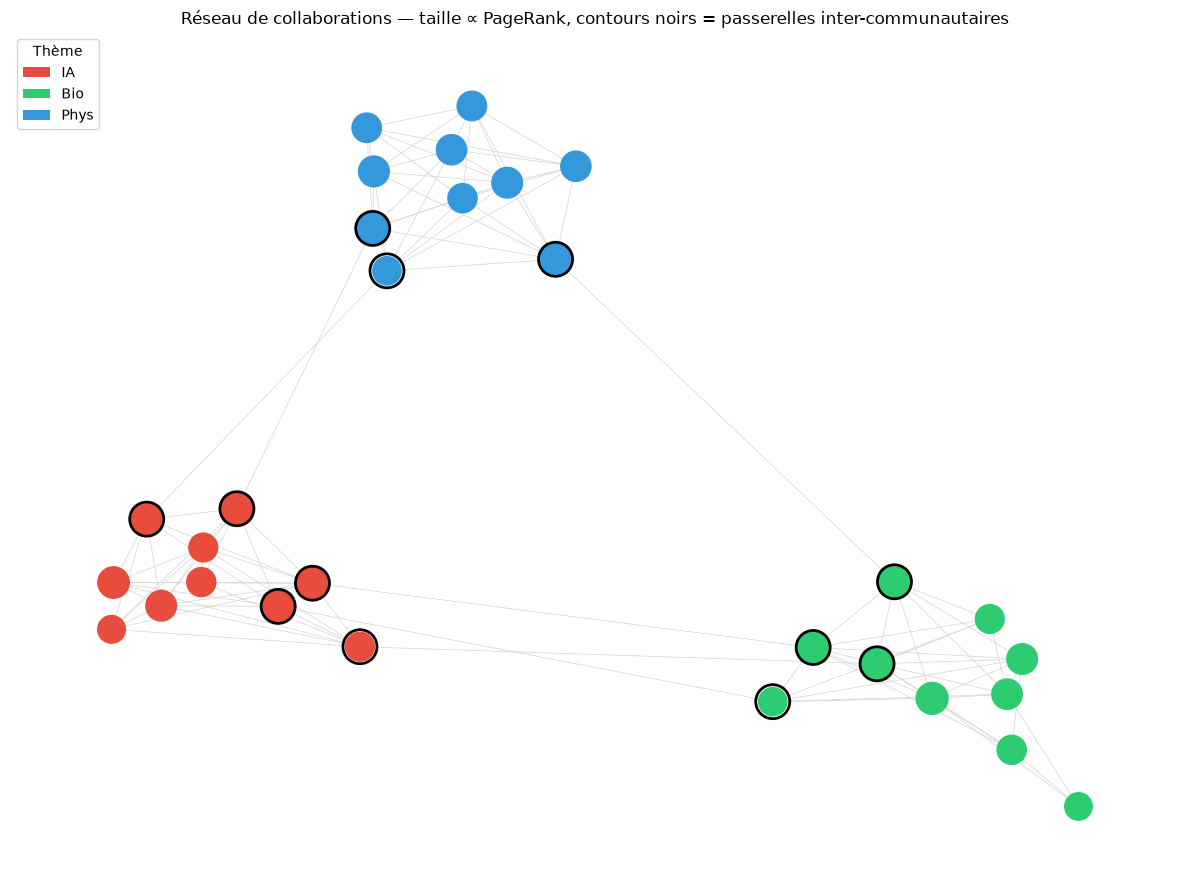

In [18]:
# Visualisation : couleur par communauté, taille par PageRank
couleurs_theme = {"IA": "#e74c3c", "Bio": "#2ecc71", "Phys": "#3498db"}
node_colors = []
node_sizes = []
for n in Collab.nodes():
    theme = n.split('_')[0]
    node_colors.append(couleurs_theme[theme])
    node_sizes.append(300 + pr[n] * 5000)

pos = nx.spring_layout(Collab, seed=42, k=0.5)

fig, ax = plt.subplots(figsize=(12, 9))
nx.draw_networkx(Collab, pos=pos, ax=ax,
                 node_color=node_colors, node_size=node_sizes,
                 edge_color='lightgray', width=0.5, with_labels=False)
nx.draw_networkx_nodes(Collab, pos=pos, nodelist=list(inter_links_set),
                       node_color='none', edgecolors='black', node_size=600, linewidths=2, ax=ax)

from matplotlib.patches import Patch
legende_elements = [Patch(facecolor=c, label=t) for t, c in couleurs_theme.items()]
ax.legend(handles=legende_elements, loc='upper left', title='Thème')
ax.set_title("Réseau de collaborations — taille ∝ PageRank, contours noirs = passerelles inter-communautaires")
ax.axis('off')
plt.tight_layout()
plt.show()


### Lecture du résultat — popularité et pontage sont orthogonaux

Le tableau trahit l'enseignement central de cette section : **PageRank et betweenness ne récompensent pas les mêmes chercheurs**. Sur les 10 places des deux top 5, seules deux sont occupées par le même sommet — `Bio_00` (PageRank #5, betweenness #2) et `IA_05` (PageRank #2, betweenness #3). Les huit autres places vont à des chercheurs absents de l'autre classement.

**Le cas `Phys_08`.** Il domine la betweenness (`0.2185`, loin devant le #2 à `0.2133`) mais est **absent du top 5 PageRank**. C'est l'archétype du *chercheur-passerelle* : sa liaison inter-communautaire (`Bio_00 — Phys_08`) porte une fraction massive des plus courts chemins entre les communautés Bio et Physique, donc tout le trafic qui franchit ce pont transite par lui. Mais comme il n'a pas plus de co-auteurs intra-Physique que ses collègues, le flux de PageRank — qui récompense le *voisinage* et non le *rôle de routeur* — ne le distingue pas. Betweenness le voit ; PageRank le rate.

**Le cas inverse `Bio_06`.** En tête du PageRank (`0.0454`) mais absent du top betweenness : un hub très cité à l'intérieur de la communauté Bio, mais qui n'est sur le chemin d'aucun plus court chemin inter-communautaire. PageRank le voit ; betweenness le rate.

**Pourquoi les passerelles dominent la betweenness.** Les sommets marqués d'un contour noir dans la visualisation sont les 12 extrémités des 6 liaisons inter-communautaires (`liens_inter`). Or **les 5 sommets du top betweenness (`Phys_08`, `Bio_00`, `IA_05`, `Phys_02`, `IA_09`) sont tous des passerelles** : la centralité de pontage détecte mécaniquement la structure communautaire que PageRank, mesure de flux global, lisse. C'est pourquoi une analyse de réseau réaliste **rapporte plusieurs centralités conjointement** plutôt qu'une seule : elles répondent à des questions différentes (« qui est cité ? » contre « qui est irremplaçable au routage ? »). À contraster avec le petit graphe routier de 6 villes de la section 5, où Paris dominait *les quatre* centralités à la fois (Degree, Betweenness, Closeness, PageRank) : sur un graphe petit et dense, les centralités concordent ; sur un graphe réaliste structuré en communautés, elles divergent — et c'est précisément cette divergence qui rend chacune informative.

## 10. Exercices

Quatre **exemples guidés** — résolus par le groupe G01 (TP1 MIS) et par le groupe G05 (TP IA2-Min2) — illustrent chacun un algorithme ; les **exercices** qui les suivent restent à votre charge.

### Exemple guidé 1 — Plus court chemin dans un réseau de transport
> **Exemple guidé — résolu par le groupe G01** (MSMIS5IN11, PR [#22969](https://github.com/jsboige/CoursIA/pull/22969), TP1 MIS)


Construisez un graphe de réseau de transports en commun (10 stations, arêtes pondérées par temps de trajet en minutes). Calculez le plus court chemin entre deux stations données. Affichez le temps total et le nombre de stations traversées.

Chemin : ['Station_A', 'Station_C', 'Station_E', 'Station_G', 'Station_I', 'Station_J'], temps : 21 min, arrêts : 6


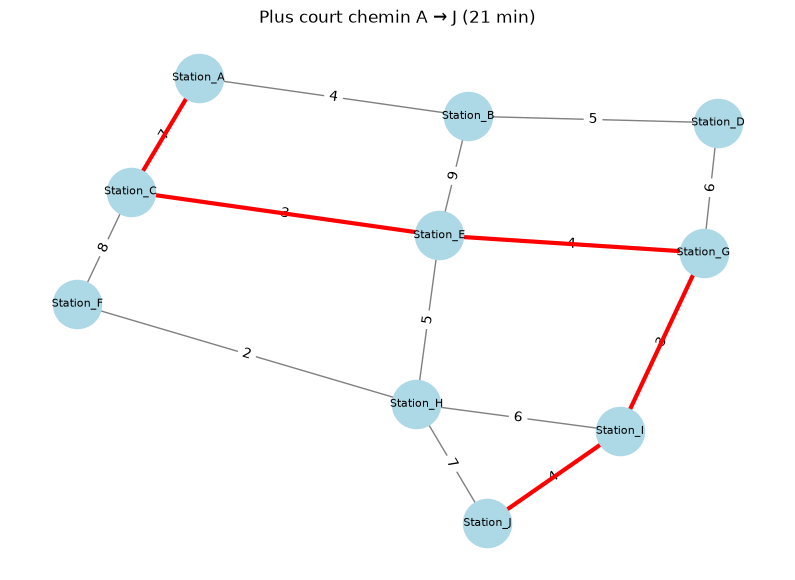

In [19]:
# Exemple guidé 1 — Plus court chemin dans un réseau de transport
# TODO : Construisez un graphe de 10 stations de métro avec arêtes pondérées
#       Calculez le plus court chemin de "Station_A" à "Station_J"
#       Affichez le temps total et le nombre de stations traversées

# Indices :
# - nx.Graph() pour un graphe non dirigé
# - nx.add_edge(u, v, weight=temps_en_min)
# - nx.shortest_path(G, source, dest, weight='weight')
# - nx.shortest_path_length(G, source, dest, weight='weight')


def exercice_1_plus_court_chemin():
    # On crée un graphe vide (non dirigé : on peut aller dans les deux sens)
    G = nx.Graph()

    # Chaque ligne = (station 1, station 2, temps de trajet en minutes)
    liaisons = [
        ("Station_A", "Station_B", 4), ("Station_A", "Station_C", 7),
        ("Station_B", "Station_D", 5), ("Station_B", "Station_E", 9),
        ("Station_C", "Station_E", 3), ("Station_C", "Station_F", 8),
        ("Station_D", "Station_G", 6), ("Station_E", "Station_G", 4),
        ("Station_E", "Station_H", 5), ("Station_F", "Station_H", 2),
        ("Station_G", "Station_I", 3), ("Station_H", "Station_I", 6),
        ("Station_H", "Station_J", 7), ("Station_I", "Station_J", 4),
    ]
    # On ajoute toutes les liaisons d'un coup, avec le temps comme "poids"
    G.add_weighted_edges_from(liaisons, weight="weight")

    # Le chemin le plus rapide de A à J (en tenant compte du temps)
    chemin = nx.shortest_path(G, "Station_A", "Station_J", weight="weight")
    # Le temps total de ce chemin
    temps = nx.shortest_path_length(G, "Station_A", "Station_J", weight="weight")
    # len(chemin) = nombre de stations traversées
    print(f"Chemin : {chemin}, temps : {temps} min, arrêts : {len(chemin)}")

    # Partie dessin
    pos = nx.spring_layout(G, seed=42)  # place les stations (seed = même dessin à chaque fois)
    fig, ax = plt.subplots(figsize=(10, 7))
    nx.draw_networkx(G, pos, ax=ax, node_color="lightblue", node_size=1200,
                     font_size=8, edge_color="gray")
    # On affiche les temps sur les arêtes
    nx.draw_networkx_edge_labels(G, pos, ax=ax,
                                 edge_labels=nx.get_edge_attributes(G, "weight"))
    # On repasse le chemin optimal en rouge
    # chemin[:-1] = toutes les stations sauf la dernière
    # chemin[1:]  = toutes les stations sauf la première
    # zip() associe les deux listes case par case : (A,C), (C,E), (E,G)...
    # list() transforme le résultat de zip en liste
    # Au final on obtient les trajets (arêtes) du chemin, pour les colorer en rouge
    aretes_chemin = list(zip(chemin[:-1], chemin[1:]))
    nx.draw_networkx_edges(G, pos, edgelist=aretes_chemin, edge_color="red", width=3, ax=ax)
    ax.set_title(f"Plus court chemin A → J ({temps} min)")
    ax.axis("off")
    plt.show()

    # On rend le graphe : l'exemple guidé 2 et l'exercice 1 le réutilisent
    return G


# On mémorise le réseau de transport pour les cellules suivantes
G = exercice_1_plus_court_chemin()

### Exemple guidé 2 — Centralité de proximité sur le même réseau
> **Exemple guidé — résolu par @oubiM** (TP IA2-Min2, groupe G05, PR [#27078](https://github.com/jsboige/CoursIA/pull/27078))

À partir du **même graphe de 10 stations** que l'exemple guidé 1, calculons la **closeness centrality** de chaque station avec `nx.closeness_centrality(G)` : un score de proximité par station, dont on déduit la station la plus « centrale » au sens de la proximité.

In [20]:
# Exemple guidé 2 — Centralité de proximité (closeness)
# Résolu par @oubiM (TP IA2-Min2, groupe G05, PR #27078) — code étudiant conservé

scores = nx.closeness_centrality(G)

for station, score in scores.items():
    print(f"{station} : {score:.3f}")

station_centrale = max(scores, key=scores.get)

print(f"\nStation la plus centrale : {station_centrale}")
print(f"Score : {scores[station_centrale]:.3f}")
print(f"Centralité de Station_J : {scores['Station_J']:.3f}")

Station_A : 0.409
Station_B : 0.500
Station_C : 0.500
Station_D : 0.429
Station_E : 0.643
Station_F : 0.450
Station_G : 0.529
Station_H : 0.562
Station_I : 0.474
Station_J : 0.429

Station la plus centrale : Station_E
Score : 0.643
Centralité de Station_J : 0.429


### Lecture du résultat — la closeness non pondérée compte des sauts, pas des minutes

`Station_E` domine (0,643 = 9/14 : la somme de ses distances en sauts vaut 14, pour 9 autres stations). Viennent `Station_H` (0,562), `Station_G` (0,529), puis `Station_B` et `Station_C` (0,500). La destination du plus court chemin de l'exemple guidé 1, `Station_J`, n'est que 9e sur 10, ex aequo avec `Station_D` (0,429) : être le but d'un trajet n'est pas être au centre du réseau.

Nuance : `nx.closeness_centrality(G)` appelée sans argument `distance` est **non pondérée** — chaque arête compte pour 1. Sur ce graphe pondéré **en minutes**, le classement ci-dessus dit donc quelle station minimise le **nombre de correspondances**, pas le **temps de trajet**. L'exercice 1 compare ce classement à la même mesure calculée en minutes.

### Exercice 1 — Centralité pondérée par le temps de trajet

Reprenez le **même graphe G** et calculez cette fois la closeness **pondérée** : `nx.closeness_centrality(G, distance="weight")` — les distances se comptent en minutes, et non plus en sauts. Comparez les **deux classements** (non pondéré ci-dessus, pondéré) : la station n°1 change-t-elle ? Citez deux stations qui changent nettement de rang entre les deux mesures, et expliquez avec les poids de leurs arêtes pourquoi elles déclinent.

In [21]:
# Exercice 1 — Centralité pondérée par le temps de trajet
# TODO : Calculez nx.closeness_centrality(G, distance="weight")
#       Affichez le classement pondéré à côté du classement non pondéré de l'exemple guidé 2.
#       Identifiez deux stations qui changent nettement de rang, et expliquez avec les poids.
# Indice : les scores pondérés sont plus petits (9 / somme des minutes) — comparez les RANGS, pas les valeurs.
#         sorted(scores_pond.items(), key=lambda x: -x[1]) donne le classement décroissant.
# VOTRE CODE ICI
pass

### Exemple guidé 3 — Centralité et communautés dans un réseau social
> **Exemple guidé — résolu par le groupe G01** (MSMIS5IN11, PR [#22969](https://github.com/jsboige/CoursIA/pull/22969), TP1 MIS)


Créez un réseau social d'au moins **15 personnes** réparties en 2-3 communautés, avec quelques liens inter-communautaires. Calculez la **betweenness centrality** et identifiez les 3 nœuds les plus "broker".

Top 3 brokers : ['David', 'Emma', 'Karim'], betweenness : [0.456, 0.288, 0.28]
Louvain : 3 communautés, modularité = 0.531


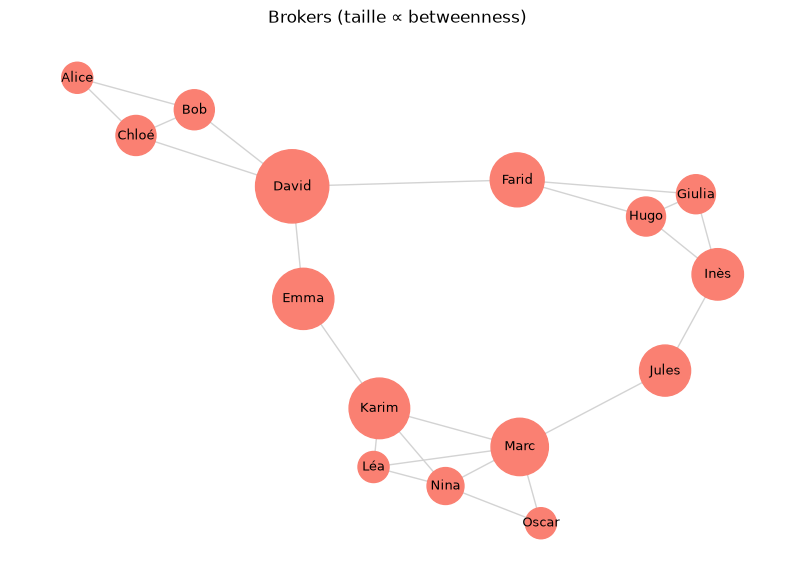


Nœud avec la plus grande betweenness : David


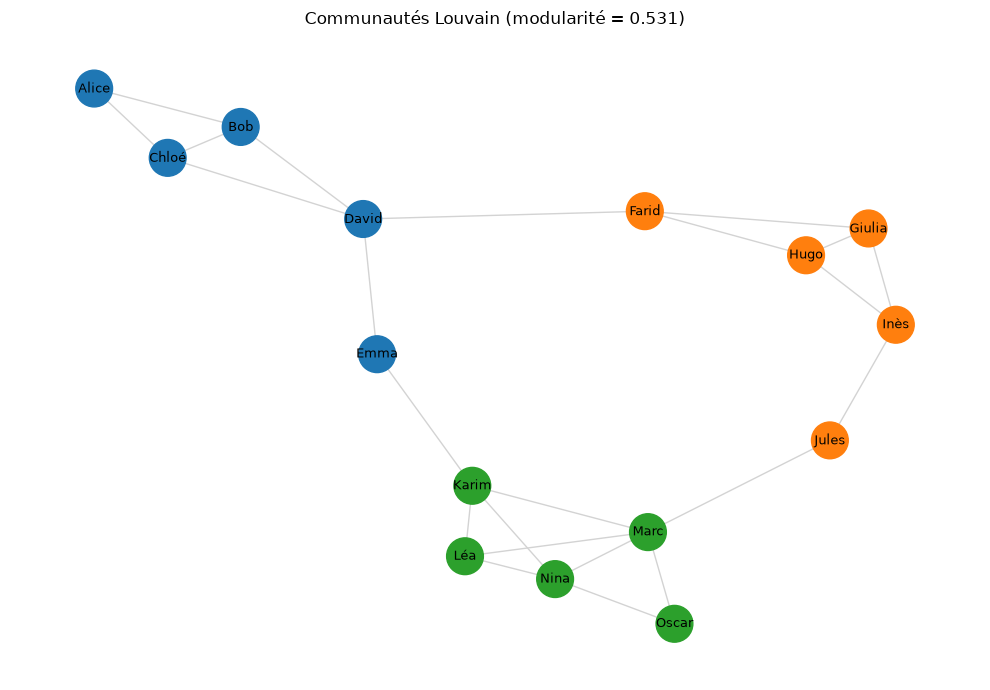

In [22]:
# Exemple guidé 3 — Détection de brokers dans un réseau social
# TODO : Construisez un graphe social de >= 15 nœuds avec 2-3 communautés
#       Calculez la betweenness centrality
#       Identifiez les 3 nœuds avec la plus grande betweenness

# Indices :
# - nx.betweenness_centrality(G)
# - sorted(centrality.items(), key=lambda x: -x[1])[:3]
# - Bonus : affichez aussi la modularité de la partition Louvain

def exercice_2_brokers_reseau_social():
    S = nx.Graph()
    # Chaque tuple = deux personnes qui sont amies
    S.add_edges_from([
        # Communauté 1
        ("Alice", "Bob"), ("Alice", "Chloé"), ("Bob", "Chloé"),
        ("Bob", "David"), ("Chloé", "David"), ("David", "Emma"),
        # Communauté 2
        ("Farid", "Giulia"), ("Giulia", "Hugo"), ("Farid", "Hugo"),
        ("Giulia", "Inès"), ("Hugo", "Inès"), ("Inès", "Jules"),
        # Communauté 3
        ("Karim", "Léa"), ("Léa", "Marc"), ("Karim", "Marc"),
        ("Marc", "Nina"), ("Nina", "Karim"), ("Nina", "Léa"),
        ("Nina", "Oscar"), ("Oscar", "Marc"),
        # Quelques liens entre les communautés (c'est eux qui font les brokers)
        ("David", "Farid"), ("Emma", "Karim"), ("Jules", "Marc"),
    ])

    # Pour chaque personne : à quel point elle sert de lien entre les autres
    bet = nx.betweenness_centrality(S)

    # On trie du plus grand au plus petit et on garde les 3 premiers
    # bet.items() donne des paires (nom, score)
    # on trie par score décroissant (le "-" met le plus grand en premier)
    # et [:3] garde les 3 meilleurs
    top3 = sorted(bet.items(), key=lambda x: -x[1])[:3]

    # on garde seulement les noms (le _ = ignore le score)
    noms = [n for n, _ in top3]

    # on garde seulement les scores, arrondis à 3 chiffres (le _ = ignore le nom)
    scores = [round(s, 3) for _, s in top3]

    print(f"Top 3 brokers : {noms}, betweenness : {scores}")

    # Louvain découpe le réseau en groupes d'amis
    comms = nx.community.louvain_communities(S, seed=42)
    # La modularité dit si le découpage est bon (proche de 1 = bien séparé)
    mod = nx.community.modularity(S, comms)
    print(f"Louvain : {len(comms)} communautés, modularité = {mod:.3f}")

    # Partie dessin 
    # Taille du rond de chaque personne : 500 (minimum) + sa betweenness * 5000
    # Plus c'est un broker, plus le rond est gros
    pos = nx.spring_layout(S, seed=42)
    tailles = [500 + bet[v] * 5000 for v in S.nodes()]
    fig, ax = plt.subplots(figsize=(10, 7))
    nx.draw_networkx(S, pos, ax=ax, node_size=tailles, node_color="salmon",
                     edge_color="lightgray", font_size=9)
    ax.set_title("Brokers (taille ∝ betweenness)")
    ax.axis("off")
    plt.show()
    print(f"\nNœud avec la plus grande betweenness : {max(bet, key=bet.get)}")

     # Une couleur par personne, selon sa communauté (dans l'ordre de S.nodes())
    couleurs_communautes = []
    for v in S.nodes():                         # pour chaque personne
        for i, comm in enumerate(comms):        # i = numéro de la communauté, comm = ses membres
            if v in comm:                       # si la personne est dans cette communauté
                couleurs_communautes.append(plt.cm.tab10(i))   # couleur n°i de la palette
                break                           # on a trouvé, on passe à la personne suivante

    fig, ax = plt.subplots(figsize=(10, 7))
    nx.draw_networkx(S, pos=pos, ax=ax,
                    node_color=couleurs_communautes, node_size=700,
                    edge_color='lightgray', font_size=9)
    # modularité mesure la qualité du découpage en communautés : 1 = bien séparé, 0 = aléatoire
    ax.set_title(f"Communautés Louvain (modularité = {mod:.3f})")
    ax.axis('off')
    plt.tight_layout()
    plt.show()

exercice_2_brokers_reseau_social()

### Exercice 2 — PageRank vs betweenness

Sur le **même réseau social** que l'exemple guidé 3, remplacez la betweenness par **`nx.pagerank(G)`**. Classez les 3 premiers « brokers » selon PageRank et commentez l'écart avec le classement par betweenness.

In [23]:
# Exercice 2 — PageRank
# TODO : Réutilisez le graphe social G de l'exemple guidé 3.
#       Calculez nx.pagerank(G), classez les 3 premiers, commentez l'écart vs betweenness.
# Indice : nx.pagerank(G, alpha=0.85) -> dict {node: score}
# VOTRE CODE ICI
pass

### Exemple guidé 4 — Flot maximum sur un réseau de pipelines
> **Exemple guidé — résolu par le groupe G01** (MSMIS5IN11, PR [#22969](https://github.com/jsboige/CoursIA/pull/22969), TP1 MIS)


Construisez un graphe dirigé représentant un réseau de pipelines (3 sources, 3 destinations, 6 nœuds intermédiaires avec capacités). Calculez le flot maximum total et affichez les arêtes saturées (flot == capacité).

In [24]:
# Exemple guidé 4 — Flot max sur réseau de pipelines
# TODO : Construisez un DiGraph de 12+ nœuds (3 sources, 3 destinations, intermédiaires)
#       Calculez le flot maximum entre super-source et super-puits
#       Listez les arêtes saturées (où flot == capacité)

# Indices :
# - nx.DiGraph()
# - nx.maximum_flow(G, source, puits, capacity='capacity')
# - Récupérer le flot sur chaque arête via T.edges(data='flow')
# - Une arête est saturée si d['flow'] == d['capacity']

def exercice_3_flot_pipelines():
    # DiGraph = graphe dirigé (le pétrole/gaz va dans un seul sens)
    P = nx.DiGraph()

    # (départ, arrivée, capacité max en unités/jour)
    aretes = [
        # sources -> nœuds intermédiaires
        ("S1", "I1", 20), ("S1", "I2", 15),
        ("S2", "I2", 25), ("S2", "I3", 10),
        ("S3", "I3", 20), ("S3", "I4", 15),
        # entre intermédiaires
        ("I1", "I5", 18), ("I2", "I5", 12), ("I2", "I6", 20),
        ("I3", "I6", 15), ("I4", "I6", 10),
        # intermédiaires -> destinations
        ("I5", "D1", 25), ("I5", "D2", 10),
        ("I6", "D2", 20), ("I6", "D3", 25),
        ("I4", "D3", 8),
    ]
    for u, v, c in aretes:
        P.add_edge(u, v, capacity=c)

    # maximum_flow accepte juste 1 source et 1 puit 
    # NetworkX veut une seule source et un seul puit : on crée un faux nœud "SuperSource" et "SuperPuit"
    # relié aux 3 vraies sources et puits (sans capacity = capacité illimitée, il ne bloque rien)
    for s in ["S1", "S2", "S3"]:
        P.add_edge("SuperSource", s)
    for d in ["D1", "D2", "D3"]:
        P.add_edge(d, "SuperPuits")

    # On calcule le flot max : flot_max = total, flot_dict = flot sur chaque arête
    flot_max, flot_dict = nx.maximum_flow(P, "SuperSource", "SuperPuits")

     # flot_dict = {départ: {arrivée: flot}}, on le parcourt avec deux boucles
    for u, voisins in flot_dict.items():      # u = nœud de départ
        for v, f in voisins.items():          # v = nœud d'arrivée, f = flot dans l'arête 
            # on stocke le flot dans l'arête pour le comparer ensuite à la capacité
            P[u][v]["flow"] = f

    # Une arête est saturée quand elle est pleine (flot == capacité)
    saturees = [(u, v) for u, v, d in P.edges(data=True)
                if "capacity" in d and d["flow"] == d["capacity"]]

    print(f"Flot max : {flot_max} unités/jour, arêtes saturées : {len(saturees)}")
    for u, v in saturees:
        print(f"  {u} → {v} ({P[u][v]['flow']}/{P[u][v]['capacity']})")

exercice_3_flot_pipelines()

Flot max : 80 unités/jour, arêtes saturées : 9
  I1 → I5 (18/18)
  I2 → I5 (12/12)
  I2 → I6 (20/20)
  S2 → I2 (25/25)
  I3 → I6 (15/15)
  S3 → I4 (15/15)
  I4 → D3 (8/8)
  I5 → D1 (25/25)
  I6 → D2 (20/20)


### Exercice 3 — Coupe minimale (max-flow / min-cut)

Sur le **même graphe de pipelines** que l'exemple guidé 4, calculez la **coupe minimale** avec `nx.minimum_cut(G, s, t)` entre la super-source et le super-puits. Vérifiez en commentaire que la capacité de la coupe vaut la valeur du flot maximum (théorème de max-flow/min-cut).

In [25]:
# Exercice 3 — Coupe minimale
# TODO : Réutilisez le DiGraph G (avec capacités) de l'exemple guidé 4.
#       Calculez nx.minimum_cut(G, s, t) ; comparez la capacité au flot maximum.
# Indice : nx.minimum_cut renvoie (capacite, (ensemble_S, ensemble_T))
# VOTRE CODE ICI
pass

## Conclusion

Ce notebook a couvert les **briques algorithmiques essentielles** de NetworkX :

| Section | Algorithmes | Complexité typique |
|---------|------------|---------------------|
| Construction | `add_node`, `add_edge`, attributs | O(1) par ajout |
| Visualisation | `spring_layout`, `circular_layout`, `kamada_kawai_layout` | O(V²) à O(V³) |
| Plus courts chemins | BFS, Dijkstra, Bellman-Ford, A*, Floyd-Warshall | O(V+E) à O(V³) |
| Centralités | Degree, Betweenness, Closeness, PageRank, Eigenvector | O(VE) à O(V³) |
| Flot maximum | Edmonds-Karp | O(VE²) |
| Communautés | Louvain | O(V log V) |
| Matching | Max-weight matching | O(V³) |

### Liens vers les autres notebooks

- **[Search-03-Informed](Search-03-Informed.ipynb)** — A\* fait main (notre implémentation pédagogique avant de passer à NetworkX)
- **[Search-08-DancingLinks](Search-08-DancingLinks.ipynb)** — couverture exacte avec Knuth DLX (graphe biparti d'incidence)
- **[Partie 2 : CSP](../Part2-CSP/README.md)** — les graphes sont le substrat des problèmes de routing et scheduling (OR-Tools, Choco)
- **[Recherche opérationnelle / SmartGrid](../../CaseStudies/Reseau-Electrique-Intelligent/README.md)** — optimisation de réseaux électriques (flot max, network simplex)

### À retenir

1. **Le graphe se mesure avant d'algorithmer** : 6 nœuds et 7 arêtes, connexe — le degré de Paris est 3, le degré moyen 2.33, la densité 0.467 et le diamètre 3. Ces quatre chiffres disent d'emblée quelle famille d'algorithmes est pertinente sur cette instance, et laquelle serait hors sujet.
2. **Le « plus court chemin » dépend de ce que l'on minimise** : de Paris à Toulouse, le trajet **pondéré** passe par Bordeaux (830 km) quand le trajet **non pondéré** passe par Lyon. Un même graphe, deux réponses : sans les poids, on compte des sauts, pas des kilomètres.
3. **Une heuristique admissible ne coûte rien en optimalité** : 660 km à vol d'oiseau vers Marseille sont bien moins que les 780 km de route, et A\* retrouve alors **exactement** l'optimum de Dijkstra ; sur la grille 5×5, il n'explore que 17 nœuds contre 25 (32 % de moins) pour le même coût de 5.905.
4. **Les centralités classent des rôles différents** : Paris domine le degré, la betweenness (0.400) et la closeness (0.714) ; Marseille est à 0.000 en betweenness ; sur le graphe de collaborations, Bio_06 domine le PageRank (0.0454) alors que Phys_08 domine la betweenness (0.2185) — deux classements orthogonaux, et Bio_00 figure dans les deux.
5. **Une arête saturée n'est pas forcément l'arête qui contraint** : le flot maximum vaut 80 t/j ; renforcer `Depot_2 → Client_X` ou `Usine_A → Depot_1` le porte à 81 t/j, mais renforcer `Depot_1 → Client_X` — déjà à 25/25 — le laisse à 80 t/j.

### Vérifiez votre compréhension

1. **Pourquoi le trajet pondéré Paris → Toulouse passe-t-il par Bordeaux, quand le trajet non pondéré passe par Lyon ?**
2. **Sur la grille 5×5, A\* a exploré 17 nœuds contre 25 pour Dijkstra, pour le même coût (5.905). Que garantit exactement l'admissibilité de l'heuristique ?**
3. **Bio_06 domine le PageRank (0.0454) et Phys_08 domine la betweenness (0.2185). Que mesurent ces deux classements, et qu'en déduire pour Bio_00 ?**
4. **Le flot maximum vaut 80 t/j et une arête est saturée à 25/25. La renforcer fait-elle monter le flot ?**

<details>
<summary>Réponses</summary>

1. Le poids d'une arête est ici une **distance routière**. Sans poids, un parcours se mesure en **nombre de sauts** : Paris → Lyon → Toulouse est le chemin le plus court en arêtes, Paris → Bordeaux → Toulouse le chemin le plus court en kilomètres. Les deux questions sont légitimes ; elles n'ont pas la même réponse.
2. Que l'heuristique **trie les nœuds dans le bon ordre sans en écarter aucun** : $h(n) \leq h^*(n)$ garantit que la priorité $f = g + h$ reste cohérente avec le coût réel, donc A\* ne peut pas fermer un nœud qui porterait l'optimum. Le gain (17 nœuds au lieu de 25) est obtenu **sans** dégrader le coût.
3. Le PageRank mesure la **popularité par citation**, la betweenness le **rôle de passerelle** (relier deux groupes). Bio_00 cumule les deux (0.0403 en PageRank, 0.2133 en betweenness) : il figure dans les deux classements. Les deux mesures ne se confondent pas.
4. **Non.** `Depot_1 → Client_X` est saturée (25/25) mais pas **contrainte** : le flot reste à 80 t/j. En revanche, `Depot_2 → Client_X` et `Usine_A → Depot_1` sont des goulots : les renforcer porte le flot à 81 t/j. Une arête saturée peut être redondante ; c'est le goulot qu'il faut tester, pas l'arête pleine.

</details>

### Pour aller plus loin

- **Carnet suivant** : [Search-02c-QuikGraph](Search-02c-QuikGraph.ipynb) — le jumeau .NET de ce carnet (QuikGraph), pour la parité structurelle Python ⇄ .NET
- **Même famille** : [Search-02-Uninformed](Search-02-Uninformed.ipynb) — BFS, DFS, UCS et IDDFS faits main, dont le chemin Paris → Toulouse non pondéré vu plus haut
- **Série voisine** : [Recherche opérationnelle / SmartGrid](../../CaseStudies/Reseau-Electrique-Intelligent/README.md) — le même modèle de flux appliqué à un réseau électrique
- **Lectures** : les papiers fondateurs déjà cités en fin de carnet — Dijkstra (1959), Bellman (1958), Edmonds & Karp (1972) pour le flot, Kamada & Kawai (1989) pour le layout
- `networkx.algorithms.approximation` — versions approchées pour graphes massifs (TSP, max-cut, clustering)
- `networkx.algorithms.tree` — forêts couvrantes minimales (Kruskal, Prim)
- `networkx.algorithms.flow` — flot min, multi-commodités, coût minimal
- `networkx.algorithms.link_analysis` — HITS, hubs and authorities
- Interopérabilité : `nx.from_numpy_array`, `nx.from_pandas_edgelist`, formats `graphml`/`gexf`/`gml`

**Référence** : [Documentation officielle NetworkX](https://networkx.org/documentation/stable/)

**Livrable équivalent C#/.NET** : voir [issue #5082](https://github.com/jsboige/CoursIA/issues/5082) pour la parité Python ⇄ .NET avec **QuikGraph** (successeur maintenu de QuickGraph, NuGet) sous .NET Interactive.

## Références

Papiers fondateurs des algorithmes de graphe embarqués par NetworkX dans ce notebook :

- **Dijkstra, E. W. (1959)**. *A Note on Two Problems in Connexion with Graphs*. Numerische Mathematik, 1:269–271. — L'algorithme de plus court chemin à poids non négatifs (`nx.shortest_path`, `dijkstra_path`).
- **Bellman, R. (1958)**. *On a Routing Problem*. Quarterly of Applied Mathematics, 16(1):87–90. — Bellman-Ford : plus court chemin avec poids négatifs (`nx.bellman_ford_path`), via la programmation dynamique.
- **Ford, L. R. & Fulkerson, D. R. (1962)**. *Flows in Networks*. Princeton University Press, pp. 130–134. — La théorie du flot maximum dont dérive Edmonds-Karp (`nx.maximum_flow`).
- **Edmonds, J. & Karp, R. M. (1972)**. *Theoretical Improvements in Algorithmic Efficiency for Network Flow Problems*. Journal of the ACM, 19(2):248–264. — La variante BFS polynomiale de Ford-Fulkerson (`nx.maximum_flow` avec méthode `edmonds-karp`).
- **Kamada, T. & Kawai, S. (1989)**. *An Algorithm for Drawing General Undirected Graphs*. Information Processing Letters, 31(1):7–15. — Le layout `kamada_kawai_layout` basé sur les distances de plus court chemin.
- **Hagberg, A., Schult, D. & Swart, P. (2008)**. *Exploring Network Structure, Dynamics, and Function using NetworkX*. Proceedings of the 7th Python in Science Conference (SciPy 2008), pp. 11–15. — La bibliothèque NetworkX elle-même (développée depuis 2004, utilisée tout au long de ce notebook).

> **Documentation** : [NetworkX officielle](https://networkx.org/documentation/stable/).
> **Algorithmes A\* et Floyd-Warshall** : approfondis dans [Search-02-Uninformed](Search-02-Uninformed.ipynb) (BFS, Dijkstra, Bellman-Ford) et [Search-03-Informed](Search-03-Informed.ipynb) (A\*, heuristiques admissibles) — implémentations pédagogiques faites main.


In [26]:
# Cellule de fermeture — vérifie que tout est en ordre
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np

print(f"✓ NetworkX {nx.__version__} chargé")
print(f"✓ Matplotlib {plt.matplotlib.__version__} chargé")
print(f"✓ NumPy {np.__version__} chargé")
print(f"\nCe notebook est prêt. Bon travail sur les exercices !")


✓ NetworkX 3.7 chargé
✓ Matplotlib 3.11.2 chargé
✓ NumPy 2.5.3 chargé

Ce notebook est prêt. Bon travail sur les exercices !
